# 06 · Calibration, cost model and decision policy

From a fraud probability to a decision: approve, review or block.

- Model: the selected gradient boosting (Phase 7), trained 2024-10-01 → 2025-06-30.
- Calibration and policy chosen on **validation** (Jul–Sep 2025) with `fraud policy optimise`.
- Everything frozen and committed (`reports/policy/policy_v1.json`, commit `32ce00c`) before
  the **single evaluation on test** (Oct–Dec 2025, `fraud policy evaluate-test`).

Cost assumptions (`configs/costs.yaml`, all of them assumptions): chargeback fee €15,
review €4, review stops 90% of the fraud it sees, €1 friction for reviewing a legit
customer, a wrongful block costs 2% of the amount + €10, 60 reviews per day.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fraudplatform.config import PROJECT_ROOT, load_cost_config
from fraudplatform.decision.costs import CostModel, evaluate_actions, threshold_actions
from fraudplatform.eda import plots

plots.apply_style()
pd.set_option("display.width", 160)
run_dir = PROJECT_ROOT / "data" / "processed" / "phase8"
policy_dir = PROJECT_ROOT / "reports" / "policy"
validation = json.loads((policy_dir / "validation_results.json").read_text(encoding="utf-8"))
test = json.loads((policy_dir / "test_evaluation.json").read_text(encoding="utf-8"))
policy = json.loads((policy_dir / "policy_v1.json").read_text(encoding="utf-8"))
cost_cfg = load_cost_config()
costs = CostModel.from_config(cost_cfg)
scores = pd.read_parquet(run_dir / "validation_scores.parquet")
print("deployed policy:", policy["policy_name"], "| calibration:", policy["calibration"])

deployed policy: P2 expected cost | calibration: {'method': 'platt', 'coef': 1.0335547672857095, 'intercept': 0.07121613175458735}


## 1. The optimal decision depends on the amount

For a calibrated probability p, each action has an expected cost. Where two lines cross,
the best action changes. A €5 payment is only worth reviewing above p ≈ 26%; a €1,000
payment is worth reviewing above 0.55% and blocking above 19%. A single global threshold
(and certainly 0.5) cannot be right for every amount.

,approve_review,review_block,approve_block
5,0.263,0.459,0.336
20,0.154,0.419,0.229
100,0.048,0.311,0.094
200,0.026,0.261,0.061
1000,0.005,0.192,0.029


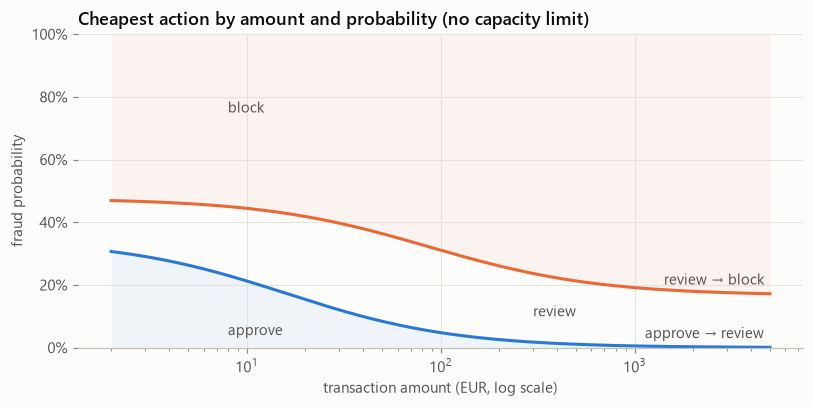

In [2]:
amounts = np.geomspace(2, 5000, 200)
bounds = pd.DataFrame([costs.breakeven(a) for a in amounts], index=amounts)
display(pd.DataFrame(validation["breakeven_examples"]).T.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(amounts, bounds["approve_review"], color=plots.BLUE)
ax.plot(amounts, bounds["review_block"], color=plots.ORANGE)
ax.fill_between(amounts, 0, bounds["approve_review"], color=plots.BLUE, alpha=0.06, linewidth=0)
ax.fill_between(amounts, bounds["review_block"], 1, color=plots.ORANGE, alpha=0.06, linewidth=0)
ax.text(8, 0.04, "approve", color=plots.INK_SECONDARY)
ax.text(300, 0.10, "review", color=plots.INK_SECONDARY)
ax.text(8, 0.75, "block", color=plots.INK_SECONDARY)
ax.annotate(
    "approve → review",
    (amounts[-1], bounds["approve_review"].iloc[-1]),
    xytext=(-4, 6),
    textcoords="offset points",
    ha="right",
    color=plots.INK_SECONDARY,
)
ax.annotate(
    "review → block",
    (amounts[-1], bounds["review_block"].iloc[-1]),
    xytext=(-4, 6),
    textcoords="offset points",
    ha="right",
    color=plots.INK_SECONDARY,
)
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_xlabel("transaction amount (EUR, log scale)")
ax.set_ylabel("fraud probability")
ax.set_title("Cheapest action by amount and probability (no capacity limit)")
fig.tight_layout()
plots.save(fig, "decision_regions_by_amount", folder="policy")
plt.show()

## 2. Is the model calibrated?

Reliability diagram on validation, each month calibrated by a calibrator fitted on the
other two (cross-fitting). Equal-count bins; log scales, because 90% of predictions are
below 0.1%.

,brier,log_loss,ece,mean_predicted,observed_rate,pr_auc
none,0.002331,0.012259,0.000346,0.00751,0.00735,0.7897
platt,0.002335,0.012257,0.000475,0.00748,0.00735,0.7897
isotonic,0.002344,0.012649,0.000520,0.00752,0.00735,0.7851


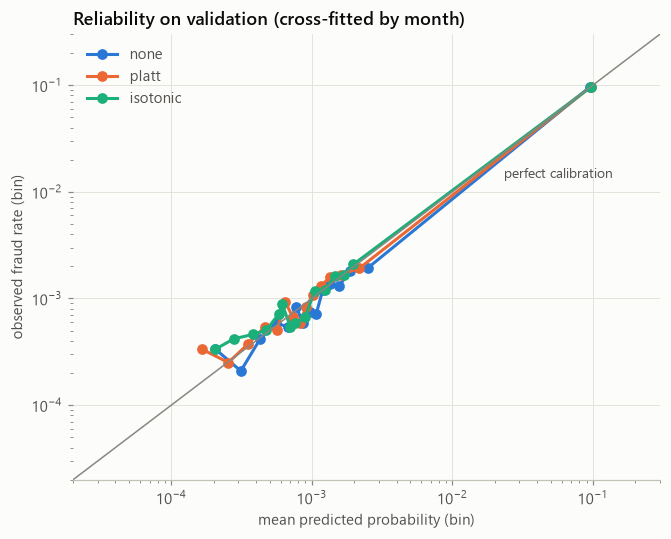

In [3]:
display(
    pd.DataFrame(validation["calibration_heldout_month"])
    .T.style.format(
        {
            "brier": "{:.6f}",
            "log_loss": "{:.6f}",
            "ece": "{:.6f}",
            "mean_predicted": "{:.5f}",
            "observed_rate": "{:.5f}",
            "pr_auc": "{:.4f}",
        }
    )
    .set_caption("Fitted on Jul–Aug, scored on Sep 2025 (forward in time)")
)
reliability = pd.read_csv(policy_dir / "reliability.csv")
fig, ax = plt.subplots(figsize=(6.2, 5.0))
for method, color in zip(
    ["none", "platt", "isotonic"], [plots.BLUE, plots.ORANGE, "#1baf7a"], strict=True
):
    r = reliability[reliability["method"] == method]
    keep = r["observed"] > 0
    ax.plot(
        r.loc[keep, "predicted"],
        r.loc[keep, "observed"],
        "o-",
        color=color,
        markersize=6,
        label=method,
    )
lims = [2e-5, 0.3]
ax.plot(lims, lims, color=plots.MUTED, linewidth=1)
ax.annotate(
    "perfect calibration",
    (0.02, 0.02),
    xytext=(6, -12),
    textcoords="offset points",
    color=plots.INK_SECONDARY,
    fontsize=9,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("mean predicted probability (bin)")
ax.set_ylabel("observed fraud rate (bin)")
ax.set_title("Reliability on validation (cross-fitted by month)")
ax.legend(loc="upper left")
fig.tight_layout()
plots.save(fig, "reliability_validation", folder="policy")
plt.show()

Equal-count bins put every prediction above ~0.4% (the region where decisions are made) in
a single bin. Fixed bins in that region, with 95% Wilson intervals on the observed rate:

In [4]:
from fraudplatform.eda.stats import wilson_interval  # noqa: E402

edges = [0, 0.001, 0.005, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
band = pd.cut(scores["p_calibrated"], edges, include_lowest=True)
table = scores.groupby(band, observed=True).agg(
    n=("is_fraud", "size"), frauds=("is_fraud", "sum"), predicted=("p_calibrated", "mean")
)
table["observed"] = table["frauds"] / table["n"]
table["ci_low"], table["ci_high"] = wilson_interval(table["frauds"], table["n"])
table.style.format(
    {
        "predicted": "{:.4f}",
        "observed": "{:.4f}",
        "ci_low": "{:.4f}",
        "ci_high": "{:.4f}",
        "n": "{:,}",
        "frauds": "{:,}",
    }
)

,n,frauds,predicted,observed,ci_low,ci_high
p_calibrated,,,,,,
"(-0.001, 0.001]","223,270",129,0.0006,0.0006,0.0005,0.0007
"(0.001, 0.005]","125,467",210,0.0017,0.0017,0.0015,0.0019
"(0.005, 0.02]","6,293",39,0.0085,0.0062,0.0045,0.0085
"(0.02, 0.05]",879,26,0.0307,0.0296,0.0203,0.0430
"(0.05, 0.1]",390,26,0.0700,0.0667,0.0459,0.0959
"(0.1, 0.2]",207,45,0.1431,0.2174,0.1666,0.2785
"(0.2, 0.4]",237,83,0.2948,0.3502,0.2923,0.4129
"(0.4, 0.7]",568,323,0.5580,0.5687,0.5276,0.6088
"(0.7, 1.0]","1,909","1,727",0.9122,0.9047,0.8907,0.9170


## 3. Expected cost as a function of the thresholds (policy P1)

Total realised cost on validation for every (review threshold, block threshold) pair,
with the 60 reviews/day capacity enforced. Left: block threshold fixed at its optimum.
Right: review threshold fixed at its optimum.

best thresholds: review >= 0.0438, block >= 0.250, cost €63,742


'block if p >= 0.5, never review': €95,162 (+49% vs optimum)


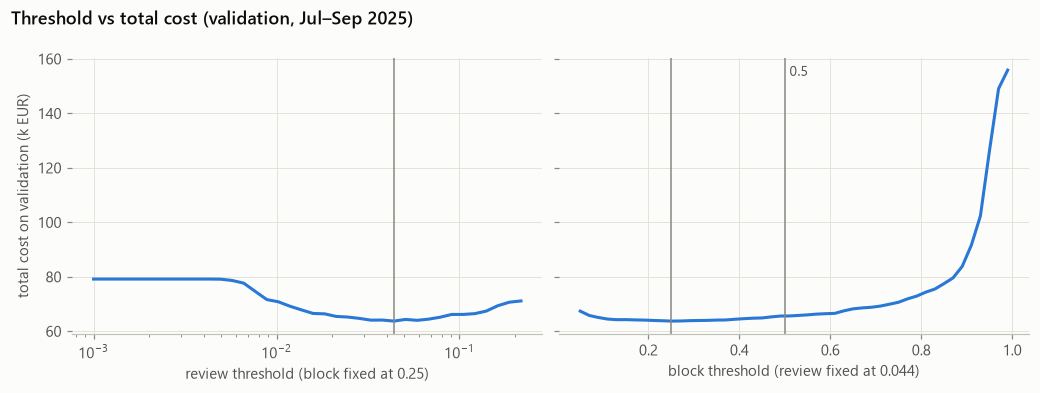

In [5]:
grid = pd.read_csv(policy_dir / "threshold_grid.csv")
best = grid.loc[grid["total_cost_eur"].idxmin()]
print(
    f"best thresholds: review >= {best['t_review']:.4f}, block >= {best['t_block']:.3f}, "
    f"cost €{best['total_cost_eur']:,.0f}"
)
y = scores["is_fraud"].to_numpy()
amount = scores["amount_eur"].to_numpy()
day = scores["ts"].dt.date.to_numpy()
realized = costs.realized(y, amount)
naive = threshold_actions(scores["p_calibrated"], day, 0.5, 0.5, cost_cfg.review_capacity_per_day)
naive_cost = evaluate_actions(naive, y, amount, realized, day, costs.reviewer_recall)
print(
    f"'block if p >= 0.5, never review': €{naive_cost['total_cost_eur']:,.0f} "
    f"({naive_cost['total_cost_eur'] / best['total_cost_eur'] - 1:+.0%} vs optimum)"
)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
row = grid[np.isclose(grid["t_block"], best["t_block"])].sort_values("t_review")
axes[0].plot(row["t_review"], row["total_cost_eur"] / 1000, color=plots.BLUE)
axes[0].axvline(best["t_review"], color=plots.MUTED, linewidth=1)
axes[0].set_xscale("log")
axes[0].set_xlabel(f"review threshold (block fixed at {best['t_block']:.2f})")
axes[0].set_ylabel("total cost on validation (k EUR)")
col = grid[np.isclose(grid["t_review"], best["t_review"])].sort_values("t_block")
col = col[col["t_block"] <= 1]
axes[1].plot(col["t_block"], col["total_cost_eur"] / 1000, color=plots.BLUE)
axes[1].axvline(best["t_block"], color=plots.MUTED, linewidth=1)
axes[1].axvline(0.5, color=plots.MUTED, linewidth=1)
axes[1].annotate(
    "0.5",
    (0.5, axes[1].get_ylim()[1]),
    xytext=(3, -12),
    textcoords="offset points",
    color=plots.INK_SECONDARY,
    fontsize=9,
)
axes[1].set_xlabel(f"block threshold (review fixed at {best['t_review']:.3f})")
fig.suptitle(
    "Threshold vs total cost (validation, Jul–Sep 2025)", x=0.01, ha="left", fontweight="semibold"
)
fig.tight_layout()
plots.save(fig, "threshold_vs_cost", folder="policy")
plt.show()

## 4. Policies compared (validation)

P1 uses one pair of thresholds for every transaction. P2 decides per transaction from the
expected cost of each action, so it uses the amount. Both get the same review capacity.

In [6]:
cols = [
    "total_cost_eur",
    "cost_per_1000_txn",
    "blocked",
    "reviewed",
    "reviews_per_day_max",
    "fraud_blocked",
    "fraud_reviewed",
    "fraud_approved",
    "legit_blocked",
    "false_decline_rate",
    "fraud_eur_stopped_share",
]
fmt = {
    "total_cost_eur": "€{:,.0f}",
    "cost_per_1000_txn": "€{:,.1f}",
    "false_decline_rate": "{:.3%}",
    "fraud_eur_stopped_share": "{:.1%}",
}
pd.DataFrame(validation["policies_validation"]).T[cols].style.format(fmt)

,total_cost_eur,cost_per_1000_txn,blocked,reviewed,reviews_per_day_max,fraud_blocked,fraud_reviewed,fraud_approved,legit_blocked,false_decline_rate,fraud_eur_stopped_share
approve_all,"€946,616","€2,635.2",0.000000,0.000000,0.000000,0.000000,0.000000,2608.000000,0.000000,0.000%,0.0%
"rules (1 rule: review, 2+: block)","€520,946","€1,450.2",1113.000000,5520.000000,60.000000,795.000000,437.000000,1376.000000,318.000000,0.089%,48.4%
P1 thresholds,"€63,742",€177.4,2651.000000,755.000000,16.000000,2124.000000,89.000000,395.000000,527.000000,0.148%,94.9%
P2 expected cost,"€62,925",€175.2,2513.000000,1279.000000,24.000000,2058.000000,121.000000,429.000000,455.000000,0.128%,95.2%


## 5. What if the assumptions are wrong?

One assumption at a time moved to 50% and 150% of its value. *Regret* = cost of keeping the
deployed policy (which still believes the original numbers) minus the cost of the policy we
would have chosen knowing the true value. Small negative values are luck: the policy
minimises *expected* cost, not the realised cost of one quarter.

,assumption,factor,value,deployed_policy_eur,best_reoptimised_eur,regret_eur,regret_pct
0,chargeback_fee,0.500000,7.5,"€59,617","€59,683",€-66,-0.1%
1,chargeback_fee,1.500000,22.5,"€66,234","€65,943",€290,+0.4%
2,review_cost,0.500000,2,"€60,367","€59,645",€723,+1.2%
3,review_cost,1.500000,6,"€65,483","€64,919",€565,+0.9%
4,reviewer_recall,0.500000,0.45,"€71,098","€66,279","€4,820",+7.3%
5,reviewer_recall,1.500000,1,"€61,109","€59,843","€1,267",+2.1%
6,review_friction,0.500000,0.5,"€62,346","€62,353",€-7,-0.0%
7,review_friction,1.500000,1.5,"€63,504","€63,090",€414,+0.7%
8,lost_margin_rate,0.500000,0.01,"€61,745","€61,744",€1,+0.0%
9,lost_margin_rate,1.500000,0.03,"€64,105","€63,928",€178,+0.3%


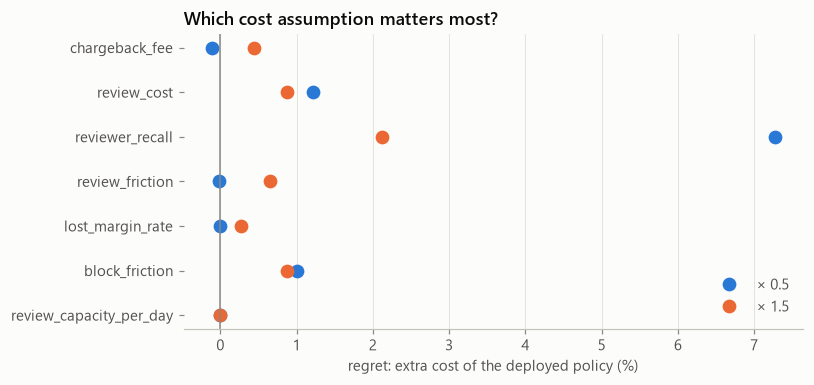

In [7]:
sens = pd.read_csv(policy_dir / "sensitivity.csv")
sens["regret_pct"] = sens["regret_eur"] / sens["best_reoptimised_eur"]
display(
    sens[
        [
            "assumption",
            "factor",
            "value",
            "deployed_policy_eur",
            "best_reoptimised_eur",
            "regret_eur",
            "regret_pct",
        ]
    ].style.format(
        {
            "value": "{:g}",
            "deployed_policy_eur": "€{:,.0f}",
            "best_reoptimised_eur": "€{:,.0f}",
            "regret_eur": "€{:,.0f}",
            "regret_pct": "{:+.1%}",
        }
    )
)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
names = list(dict.fromkeys(sens["assumption"]))
ypos = {n: i for i, n in enumerate(names[::-1])}
for factor, color, label in [(0.5, plots.BLUE, "× 0.5"), (1.5, plots.ORANGE, "× 1.5")]:
    s = sens[sens["factor"] == factor]
    ax.plot(
        100 * s["regret_pct"],
        [ypos[n] for n in s["assumption"]],
        "o",
        color=color,
        markersize=8,
        label=label,
    )
ax.axvline(0, color=plots.MUTED, linewidth=1)
ax.set_yticks(list(ypos.values()), list(ypos.keys()))
ax.grid(axis="y", visible=False)
ax.set_xlabel("regret: extra cost of the deployed policy (%)")
ax.set_title("Which cost assumption matters most?")
ax.legend(loc="lower right")
fig.tight_layout()
plots.save(fig, "sensitivity_regret", folder="policy")
plt.show()

## 6. The single evaluation on test (Oct–Dec 2025)

In [8]:
model_cols = [
    "pr_auc",
    "pr_auc_ci_low",
    "pr_auc_ci_high",
    "roc_auc",
    "precision_at_alert_rate",
    "recall_at_alert_rate",
    "amount_recall_at_alert_rate",
    "brier",
    "mean_predicted",
]
print(
    f"test: {test['transactions']:,} transactions, {test['frauds']:,} frauds "
    f"(base rate {test['base_rate']:.3%})"
)
display(
    pd.Series({k: test["model"][k] for k in model_cols}).to_frame("test").T.style.format("{:.4f}")
)
print(f"validation PR-AUC of the same model: {validation['validation_raw_pr_auc']:.4f}")
pd.DataFrame(test["policies"]).T[cols].style.format(fmt)

test: 387,978 transactions, 2,857 frauds (base rate 0.736%)


,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,precision_at_alert_rate,recall_at_alert_rate,amount_recall_at_alert_rate,brier,mean_predicted
test,0.7523,0.7180,0.7767,0.9526,0.8871,0.6024,0.8377,0.0025,0.0073


validation PR-AUC of the same model: 0.7921


,total_cost_eur,cost_per_1000_txn,blocked,reviewed,reviews_per_day_max,fraud_blocked,fraud_reviewed,fraud_approved,legit_blocked,false_decline_rate,fraud_eur_stopped_share
approve_all,"€946,956","€2,440.7",0.000000,0.000000,0.000000,0.000000,0.000000,2857.000000,0.000000,0.000%,0.0%
"rules (1 rule: review, 2+: block)","€482,886","€1,244.6",1279.000000,5520.000000,60.000000,912.000000,443.000000,1502.000000,367.000000,0.095%,52.7%
P1 thresholds (frozen),"€66,962",€172.6,2903.000000,791.000000,17.000000,2289.000000,102.000000,466.000000,614.000000,0.159%,94.8%
"P2 expected cost (frozen, deployed)","€64,098",€165.2,2737.000000,1426.000000,30.000000,2195.000000,164.000000,498.000000,542.000000,0.141%,95.5%


## 7. Findings

Full write-up: [`reports/policy/phase8_findings.md`](../reports/policy/phase8_findings.md).

- Thresholds must depend on the amount; the "default" 0.5 costs 49% more than the optimum.
- The model was already calibrated (no class weights); Platt ≈ identity, isotonic overfits.
  Weak spot: 10–20% predicted vs 21.7% observed, on 207 transactions.
- Deployed: expected cost per transaction (P2), €62,925 on validation vs €946,616 approving
  everything. Review capacity never binds.
- Most sensitive assumption: how much fraud a review stops (+7.3% regret if it is 45%).
- Test, evaluated once: PR-AUC 0.752 (validation 0.792), but the policy cost (€64,098) and
  the share of fraud EUR stopped (95.5%) held up.